In [54]:
import matplotlib.pyplot as plt
import numpy as np
import pandas
import scipy

In [14]:
df = pandas.read_csv("../../results/ancestry/DGRP-3_ancestry.tsv", sep="\\s+")
arr = np.array(df)[:, 2:].astype(int)
p_afr = np.sum(arr == 1, axis=1) / np.sum(arr >= 0, axis=1)
chroms = list(df["chrom"])
positions = np.array(df["position"])

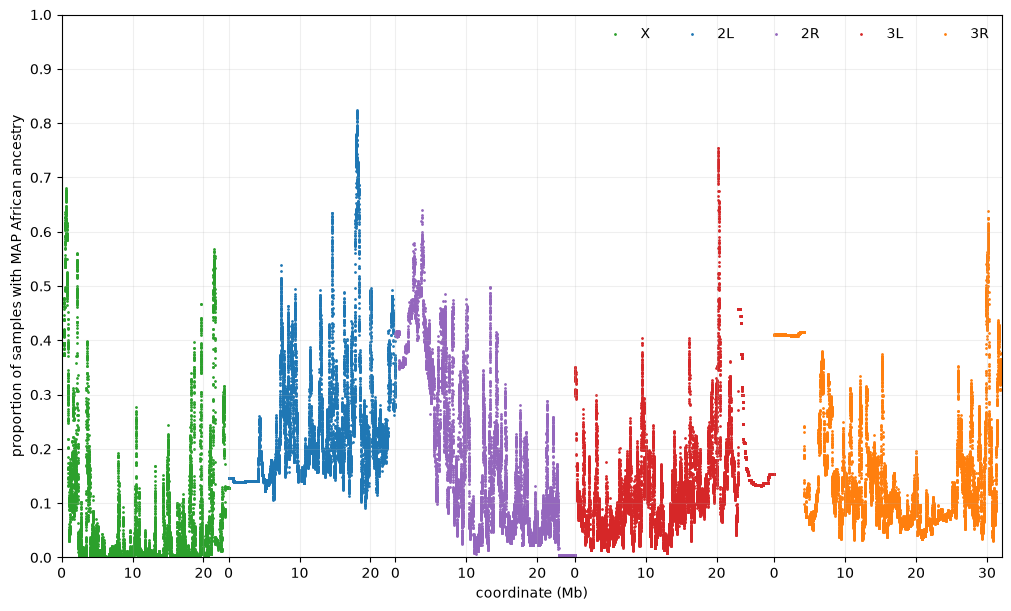

In [71]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6), layout="constrained")

colors = ["tab:green", "tab:blue", "tab:purple", "tab:red", "tab:orange"]
split_points = [0]
xticks = []
xtick_labels = []
for i, chrom in enumerate(["X", "2L", "2R", "3L", "3R"]):
    mask = np.array([c == chrom for c in chroms])
    xs = positions[mask] + split_points[-1]
    ys = p_afr[mask]
    plt.scatter(xs, ys, s=1, color=colors[i], label=chrom)
    _xticks = np.arange(0, positions[mask][-1], 10_000_000)
    xtick_labels += list(_xticks)
    xticks += list(_xticks + split_points[-1])
    split_points.append(xs[-1])

ax.legend(framealpha=0, ncols=5)
ax.set_ylim(0, 1)
ax.set_xlim(0, split_points[-1])
ax.grid(alpha=0.2)
# xticks = np.arange(0, 140_000_000, 10_000_000)
ax.set_xticks(xticks, (np.array(xtick_labels) / 1e6).astype(int))
ax.set_xlabel("coordinate (Mb)")
ax.set_yticks(np.linspace(0, 1, 11))
ax.set_ylabel("proportion of samples with MAP African ancestry")
plt.savefig("../../figures/African_ancestry_landscape_v0.png", dpi=244)
plt.savefig("../../figures/African_ancestry_landscape_v0.pdf")

In [96]:
def count_types(locusA, locusB):
    chromA, (startA, stopA) = locusA
    chromB, (startB, stopB) = locusB
    dfA = df[
        (df["chrom"] == chromA)
        & (df["position"] >= startA) 
        & (df["position"] <= stopA)]
    dfB = df[
        (df["chrom"] == chromB)
        & (df["position"] >= startA) 
        & (df["position"] <= stopA)]
    samples = list(df.columns[2:])
    comparisons = []
    type_counts = []
    p_fets = []
    for i, rowA in dfA.iterrows():
        for j, rowB in dfB.iterrows():
            siteA = f"{rowA['chrom']}:{rowA['position']}"
            siteB = f"{rowB['chrom']}:{rowB['position']}"
            comparisons.append((siteA, siteB))
            AA, AE, EA, EE = 0, 0, 0, 0
            for sample in samples:
                ancA = rowA[sample]
                ancB = rowB[sample]
                if ancA == 1 and ancB == 1:
                    AA += 1
                elif ancA == 1 and ancB == 0:
                    AE += 1
                elif ancA == 0 and ancB == 1:
                    EA += 1
                elif ancA == 0 and ancB == 0:
                    EE += 1
            type_counts_ij = [AA, AE, EA, EE]
            type_counts.append(type_counts_ij)
            table = np.reshape(type_counts_ij, (2, 2))
            p_fet = scipy.stats.fisher_exact(table, alternative="greater").pvalue
            p_fets.append(p_fet)
    for comp, counts, p_fet, in zip(comparisons, type_counts, p_fets):
        print(comp, counts, sum(counts), p_fet)
    
    return comparisons, type_counts

In [97]:
# Build 5: X:20,815,287..20,820,196 x 3L:4,416,058..4,419,369
# Build 6: X:20,944,260..20,949,169 x 3L:4,416,058..4,419,369
ret = count_types(
    ("X", (20_944_260, 20_949_169)),
    ("3L", (4_416_058, 4_419_369)),
)

('X:20946115', '3L:20944916') [26, 183, 94, 691] 994 0.46746394520674045
('X:20946115', '3L:20946451') [23, 185, 91, 692] 991 0.6302537911025885
('X:20946115', '3L:20947804') [23, 184, 91, 700] 998 0.6039872458352689
('X:20946115', '3L:20949099') [26, 183, 96, 692] 997 0.500105572740394
('X:20947140', '3L:20944916') [25, 180, 95, 696] 996 0.5118936802141782
('X:20947140', '3L:20946451') [22, 182, 92, 697] 993 0.6765548407401887
('X:20947140', '3L:20947804') [22, 181, 92, 705] 1000 0.65169723311171
('X:20947140', '3L:20949099') [26, 180, 97, 697] 1000 0.47759029870235464
('X:20948224', '3L:20944916') [24, 183, 96, 700] 1003 0.6131868682399286
('X:20948224', '3L:20946451') [22, 185, 93, 701] 1001 0.7071667362664784
('X:20948224', '3L:20947804') [22, 184, 93, 709] 1008 0.6833940615833196
('X:20948224', '3L:20949099') [26, 182, 97, 701] 1006 0.4864640086032347


In [99]:
tab = np.array([[26, 183], [94, 691]])
print(tab / np.sum(tab), tab.sum(0) / np.sum(tab), tab.sum(1) / np.sum(tab))
print(np.outer(tab.sum(1) / np.sum(tab), tab.sum(0) / np.sum(tab)))

[[0.02615694 0.18410463]
 [0.0945674  0.69517103]] [0.12072435 0.87927565] [0.21026157 0.78973843]
[[0.02538369 0.18487788]
 [0.09534066 0.69439777]]


In [79]:
# Build 5: 2R:11,353,691..11,359,516 x 3L:11,079,088..11,085,304
# Build 6: 2R:15,466,186..15,472,011 x 3L:11,085,988..11,092,204

ret = count_types(
    ("2R", (15_466_186, 15_472_011)),
    ("3L", (11_085_988, 11_092_204)),
)

('2R:15466362', '3L:15466529') [22, 281, 38, 604] 945 0.2562837308346871
('2R:15466362', '3L:15467883') [21, 281, 38, 604] 944 0.3156677131889624
('2R:15466362', '3L:15469514') [21, 282, 36, 606] 945 0.2547758580568212
('2R:15466362', '3L:15470535') [21, 283, 42, 604] 950 0.45642813210934213
('2R:15467604', '3L:15466529') [21, 277, 38, 609] 945 0.28816422736395025
('2R:15467604', '3L:15467883') [20, 276, 38, 610] 944 0.34569584139425447
('2R:15467604', '3L:15469514') [20, 277, 36, 612] 945 0.28281284191209743
('2R:15467604', '3L:15470535') [20, 278, 42, 610] 950 0.48803396953782197
('2R:15468752', '3L:15466529') [22, 272, 38, 612] 944 0.20729615133854856
('2R:15468752', '3L:15467883') [21, 271, 38, 613] 943 0.2553587266767965
('2R:15468752', '3L:15469514') [21, 272, 36, 615] 944 0.202016771219001
('2R:15468752', '3L:15470535') [21, 272, 43, 613] 949 0.41213961074985206
('2R:15469835', '3L:15466529') [21, 285, 39, 625] 970 0.3217300036646693
('2R:15469835', '3L:15467883') [20, 284, 39, 

In [100]:
ret = count_types(
    ("X", (2_000_000, 2_005_000)),
    ("X", (18_500_000, 18_505_000)),
)

('X:2001327', 'X:2001327') [126, 0, 0, 1079] 1205 1.2972363635256291e-174
('X:2001327', 'X:2002361') [116, 0, 0, 1078] 1194 1.2776919424694278e-164
('X:2001327', 'X:2003573') [124, 0, 6, 1033] 1163 5.9668308812845875e-161
('X:2002361', 'X:2001327') [116, 0, 0, 1078] 1194 1.2776919424694278e-164
('X:2002361', 'X:2002361') [118, 0, 0, 1084] 1202 6.63058674582263e-167
('X:2002361', 'X:2003573') [116, 0, 9, 1033] 1158 8.201762127507348e-150
('X:2003573', 'X:2001327') [124, 6, 0, 1033] 1163 5.9668308812845875e-161
('X:2003573', 'X:2002361') [116, 9, 0, 1033] 1158 8.201762127507348e-150
('X:2003573', 'X:2003573') [139, 0, 0, 1035] 1174 9.896268403349145e-185


In [106]:
ret = count_types(
    ("2L", (10_000_000, 10_005_000)),
    ("2L", (20_000_000, 20_005_000)),
)

('2L:10000485', '2L:10000485') [152, 0, 0, 811] 963 1.1939270367304788e-181
('2L:10000485', '2L:10001492') [151, 0, 0, 811] 962 7.564156160338498e-181
('2L:10000485', '2L:10002644') [152, 0, 0, 811] 963 1.1939270367304788e-181
('2L:10000485', '2L:10003758') [152, 0, 0, 811] 963 1.1939270367304788e-181
('2L:10001492', '2L:10000485') [151, 0, 0, 811] 962 7.564156160338498e-181
('2L:10001492', '2L:10001492') [151, 0, 0, 811] 962 7.564156160338498e-181
('2L:10001492', '2L:10002644') [151, 0, 0, 811] 962 7.564156160338498e-181
('2L:10001492', '2L:10003758') [151, 0, 0, 811] 962 7.564156160338498e-181
('2L:10002644', '2L:10000485') [152, 0, 0, 811] 963 1.1939270367304788e-181
('2L:10002644', '2L:10001492') [151, 0, 0, 811] 962 7.564156160338498e-181
('2L:10002644', '2L:10002644') [153, 0, 0, 812] 965 1.594486695496397e-182
('2L:10002644', '2L:10003758') [153, 0, 0, 811] 964 1.894925691076384e-182
('2L:10003758', '2L:10000485') [152, 0, 0, 811] 963 1.1939270367304788e-181
('2L:10003758', '2L: